# kine's elytra flight, simulated

This notebook flies the mod's flight laws in Python: the autopilot's porpoise (its climb and its altitude hold), the
holding circle, the aimed landing and the rocket takeoff. They run on `kine_flight.py`, a line-for-line copy of the
mod's pure flight classes (`src/main/java/ai/rrw/kine/autoflight/` and `fireworks/`), checked against the compiled Java
tick for tick, so what flies here is what the mod flies, up to the limits in the last section.

It also holds the study that found today's porpoise law (2026-10-11). The question was whether a faster autopilot
pitch would make the porpoise more efficient; the answer was that the law's shape mattered more than its speed. A
law that levels off at the bottom of each dive before pulling up climbs 61% faster and cruises 8% faster than the law
the mod flew from June. The study's search results are in `fastpitch_study.csv`, re-flown and rerun below.

**Files in this folder**
- `elytra_flight_model.ipynb`: this notebook.
- `kine_flight.py`: the Python copy of the flight code, plus the study's measures and search objectives.
- `fastpitch_study.csv`: the study's 493 search runs, one per law shape, pitch response and seed, with the measures
  and the parameters to re-fly each.
- `JavaTrace.java` and `validate_against_java.py`: fly the compiled mod and the Python side by side and compare every
  tick (`./gradlew compileJava`, then `python3 python_sim/validate_against_java.py`).

**Running it** needs Python 3 with numpy, scipy and matplotlib. The two searches in section 7 run on 8 processes and
take about a minute; everything else takes seconds.

**Conventions**, the mod's and the game's: lengths in blocks, time in ticks (20 a second), so m/s = blocks a tick x 20.
Yaw 0 faces +Z and 90 faces -X. Pitch is Minecraft's: positive is nose down. Plots show degrees above the horizon
(minus the pitch) where that reads better.

**Contents**
1. The copy is the mod
2. The physics
3. The autopilot's pitch response
4. The porpoise law
5. Climb and cruise, June's law and today's
6. Why levelling off works: the energy budget
7. The study that found it
8. Disturbances: a frozen second, a lag spike
9. What other code takes from the porpoise
10. Turning
11. The holding circle
12. The aimed landing
13. The rocket takeoff
14. Rockets that hit their own player
15. Limits

In [1]:
import csv, math, os, sys, time
sys.dont_write_bytecode = True            # no __pycache__ in the repo,
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"   # nor from the search's worker processes
import numpy as np
import matplotlib.pyplot as plt
import kine_flight as kf
%matplotlib inline
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("kine_flight copied from commit", kf.COPIED_FROM)

kine_flight copied from commit 1ebaf05


## 1. The copy is the mod

kine's own unit tests pin a few traces and numbers: `FlightModel3DTest`'s two golden traces (a climb and a turn,
to 1e-9), `RocketHitTest`'s hits, `TakeoffModelTest`'s steady rocket climb and rocket count, `HoldModelTest`'s look
offsets. The Python must reproduce them all.

`validate_against_java.py` goes further: it runs the compiled Java and the Python on ten cases (a 4,000-tick climb and
capture, a turn, the holding circle, an aimed landing, a rocket takeoff, the rocket hit map for both arms, the safe
headings, the landing-time table) and compares every number. At commit 1ebaf05 the largest difference anywhere was
4e-13 blocks, in the holding circle (Java's and C's sine can differ in the last bit); every phase, hit tick and
rocket count was identical.

In [2]:
checks = []
def check(name, ok, detail=""):
    checks.append((name, ok, detail))

# FlightModel3DTest: straightFlightStaysOnItsLineAndMatchesTheGoldenTrace
s = kf.State(0, 200, 0, 0, -0.5, 1.5, 350, 20, True); s.cmd = 40
golden = {100: (190.50952971070458, 183.10516377411867), 200: (241.04912355476148, 224.9065134610902),
          300: (190.94381718219844, 367.9629869644756), 400: (262.9273899972791, 492.0633073202938),
          500: (242.31611420777938, 560.596276811804), 600: (214.39079497653293, 746.9589539287169)}
err, pulls, prev = 0.0, 0, s.phase
for t in range(1, 601):
    kf.step(s, 0.0)
    pulls += prev == kf.DIVE and s.phase != kf.DIVE; prev = s.phase
    if t in golden: err = max(err, abs(s.y - golden[t][0]), abs(s.z - golden[t][1]))
check("climb golden trace (y, z at 6 ticks)", err < 1e-9 and pulls == 3, f"largest error {err:.1e}, {pulls} pull-ups")

# FlightModel3DTest: turningConvergesOnTheTargetHeadingAndMatchesTheGoldenTrace
s = kf.State(0, 300, 0, 0, -0.5, 1.5, 300, 20, False); s.cmd = 38
golden = {50: (-29.674080254107317, 313.9269100636415, 37.680810521284045),
          100: (-43.049185805217334, 317.72477305933614, 38.130478836228704),
          300: (-319.4165977846555, 298.3076599306456, 38.131885316882496)}
err = 0.0
for t in range(1, 301):
    kf.step(s, 90.0)
    if t in golden: err = max(err, *(abs(a - b) for a, b in zip((s.x, s.y, s.z), golden[t])))
check("turn golden trace (x, y, z at 3 ticks)", err < 1e-9, f"largest error {err:.1e}")

# RocketHitTest
check("rocket at yaw 167, right arm: hits at life 4", kf.rocket_hit_tick(167, -70, True, 1.7) == 4)
check("rocket at yaws 145 and 205: no hit", kf.rocket_hit_tick(145, -70, True, 1.7) == -1 and kf.rocket_hit_tick(205, -70, True, 1.7) == -1)
check("never straight up", not any(kf.rocket_hits(y, -90, arm) for y in range(0, 360, 5) for arm in (True, False)))

# TakeoffModelTest
v = [0.0, 0.0, 0.0]
for _ in range(400):
    kf.physics_step(0, -90, v); moved = v[1]; kf.boost(0, -90, v)
check("straight-up climb under a rocket: 1.4796 blocks a tick", abs(moved - 1.4796) < 1e-3, f"{moved:.4f}")
p = kf.takeoff(0.5, 64, 0.5, 0, 350, 27, lambda x, z: 64.0, 319, 3000)
check("takeoff from flat ground at 64: reaches the cruise on 7 or 8 rockets", p["reaches_cruise"] and 7 <= p["rockets"] <= 8, f"{p['rockets']} rockets")

# HoldModelTest
check("hold look offsets", abs(kf.hold_look_yaw(0, 100, 0, 0, 180.0, False) - 185.0) < 1e-9
      and abs(kf.hold_look_yaw(0, 100, 0, 0, 0.0, False) - 9.0) < 1e-9 and abs(kf.hold_look_yaw(0, 100, 0, 0, 0.0, True) - 5.0) < 1e-9)

for name, ok, detail in checks:
    print(("ok    " if ok else "FAIL  ") + name + (f"   ({detail})" if detail else ""))
assert all(ok for _, ok, _ in checks)

ok    climb golden trace (y, z at 6 ticks)   (largest error 0.0e+00, 3 pull-ups)
ok    turn golden trace (x, y, z at 3 ticks)   (largest error 0.0e+00)
ok    rocket at yaw 167, right arm: hits at life 4
ok    rocket at yaws 145 and 205: no hit
ok    never straight up
ok    straight-up climb under a rocket: 1.4796 blocks a tick   (1.4796)
ok    takeoff from flat ground at 64: reaches the cruise on 7 or 8 rockets   (8 rockets)
ok    hold look offsets


## 2. The physics

`LivingEntity.updateFallFlyingMovement` (26.1.2, lines 2543 to 2568 of the decompile), as `FlightModel3D.physicsStep`
copies it. Each tick, with the look at pitch $\theta$ (positive nose down), $\text{lift} = \cos^2\theta$, the
horizontal look direction $\hat{h}$, the horizontal speed $h_0$ at the start of the tick and $g = 0.08$:

1. **Gravity less lift.** $v_y \mathrel{+}= g\,(-1 + 0.75\,\text{lift})$. Level flight cancels three quarters of
   gravity.
2. **The descent redirect.** While sinking ($v_y < 0$): $c = -0.1\,\text{lift}\,v_y$; $v_y \mathrel{+}= c$ and
   $c$ goes into forward speed along $\hat{h}$. A tenth of the sink becomes forward speed each tick, most with the nose
   level, nearly none with the nose 60 degrees up.
3. **The pump.** With the nose up ($\theta < 0$): $c = 0.04\,h_0\,\sin(-\theta)$ is taken from forward speed and
   $3.2\,c$ added to the climb. This is where a zoom's height comes from, and it grows with forward speed.
4. **Steering.** The horizontal velocity moves 10% of the way toward the look's heading at the same speed. In
   straight flight it gives back a tenth of the tick's change in forward speed; off the velocity's heading it turns
   the aircraft, and the turn costs a little speed.
5. **Drag.** Horizontal speed times 0.99, vertical times 0.98.

A wall hit deals the horizontal speed lost times 10, less 3. While gliding, any tick sinking slower than 0.5 blocks a
tick resets the fall distance to 1 (`Entity.checkFallDistanceAccumulation`), so a touchdown sinking under 10 m/s does
no fall damage.

The porpoise lives on terms 2 and 3: dive to build speed (the redirect turns the dive's sink into forward speed), then
zoom (the pump turns forward speed into height at 3.2 times its cost). Section 6 books every term over a cycle.

## 3. The autopilot's pitch response

Each tick the autopilot moves the flown pitch toward the law's command. Until 2026-10-11 it moved 0.15 of the gap, at
most 7 degrees a tick; now it moves straight at the command at up to 15 degrees a tick (300 deg/s,
`FlightModel3D.SMOOTH 1.0, CAP 15`). The landing keeps its own 0.15 / 7, the response its law was tuned on.

Why 15 and not instant: every rotation the mod sends must be one a human could make (RW's rule since June: no faster
than a person). The study estimated a fast flick at about 30 degrees a tick averaged over the flick, at a common
shooter sensitivity (hand speeds from Hsieh, Liu and Newell 2017; sensitivities from Boudaoud, Spjut and Kim 2022); kine's
emergency bank already turns at 22.5. Section 7 shows that past 15 to 20 a tick nothing more is gained.

The plot is one pull-up command (from 44 degrees nose down to 80 nose up) under each response.

June: 0.15 of the gap, at most 7 a tick    reaches 70 deg up in 21 ticks
now: 15 deg a tick                         reaches 70 deg up in 8 ticks
instant                                    reaches 70 deg up in 1 ticks


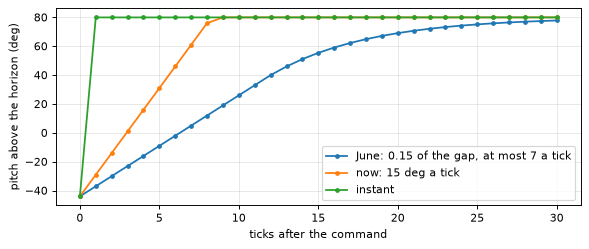

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for resp, label in ((kf.JUNE_RESPONSE, "June: 0.15 of the gap, at most 7 a tick"),
                    (kf.PORPOISE_RESPONSE, "now: 15 deg a tick"),
                    (kf.Response(1.0, 180.0), "instant")):
    pitch, ps = 44.0, [44.0]
    for _ in range(30):
        pitch = resp.ease(pitch, -80.0); ps.append(pitch)
    ax.plot(range(31), [-p for p in ps], marker=".", label=label)
    print(f"{label:42s} reaches 70 deg up in {next(i for i, p in enumerate(ps) if p <= -70)} ticks")
ax.set_xlabel("ticks after the command"); ax.set_ylabel("pitch above the horizon (deg)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. The porpoise law

`PorpoiseLaw` commands one pitch a tick. It dives at a fixed pitch; at the bottom it **levels off** for 13 ticks, which
lets the redirect turn the dive's sink into forward speed; then it **pulls up** hard, **eases** the nose back down
toward a shallow climb, **glides** at a shallow dive and returns to the **dive**. Everything after the pull-up is a
program of ticks since the trigger, so a rollout that copies the law (the terrain planner, the rails) continues it
exactly.

Below the target altitude it flies the CLIMB profile, which pulls up at a trigger speed. At or above it, the ALT_HOLD
profile, which dives until it is within DESC_MARGIN of the target, so every trough lands just above it (the level-off
carries the true trough about 6 blocks below the pull-up). Which profile the next cycle flies is decided at each
pull-up, from the lowest altitude since the last one.

June's law (in the mod until 2026-10-11, commit 3151213 replaced it) had five numbers a profile: step to the pull-up
pitch, hold it, sweep back down at a fixed rate, dive. The pitch response's lag shaped its rotation.

the level-off law, 15 deg a tick (in the mod)
  CLIMB     dive 44.3 down, pull up at 44.1 m/s; level for 13 ticks; 78.5 up for 3; ease 0.0336 of the gap toward 6.9 up for 86; glide 32.9 down for 81
  ALT_HOLD  dive 44.5 down, pull up on altitude; 0.1 down for 13 ticks; 82.7 up for 1; ease 0.0219 of the gap toward 12.6 down for 84; glide 37.6 down for 173
  DESC_MARGIN 8.7

the June law, 0.15 / 7 (until 2026-10-11)
  CLIMB     dive 40.0 down, pull up at 44.0 m/s: 62.0 up for 11 ticks, sweep back 0.9 deg a tick
  ALT_HOLD  dive 38.0 down, pull up on altitude: 66.0 up for 13 ticks, sweep back 1.2 deg a tick
  DESC_MARGIN 6.0

the June law, 0.15 / 7 (until 2026-10-11): +11.32 blocks a cycle, nose up to 52.4 deg, fastest pitch change 7.0 deg a tick


the level-off law, 15 deg a tick (in the mod): +18.91 blocks a cycle, nose up to 73.8 deg, fastest pitch change 15.0 deg a tick


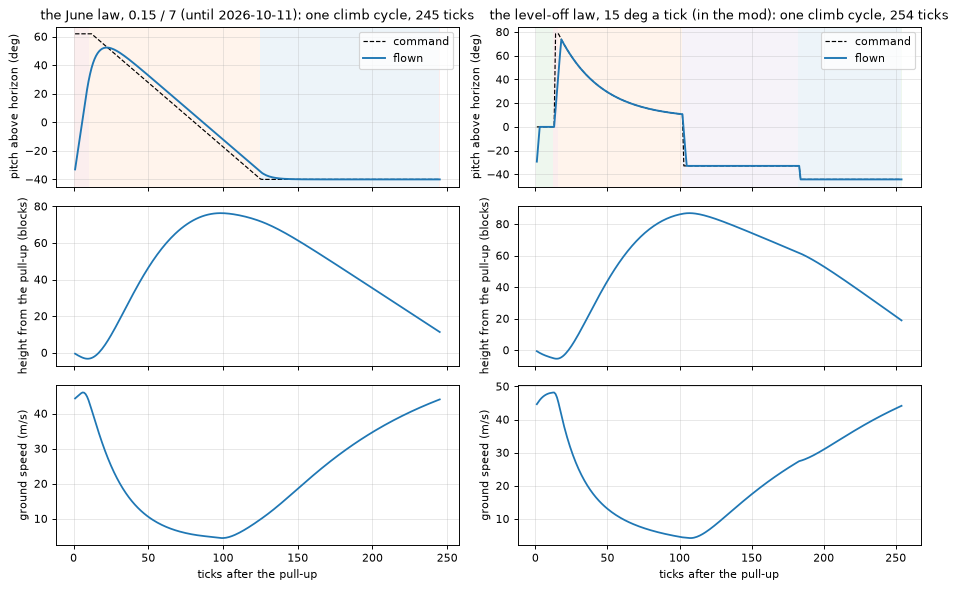

shading: green level, red pull-up, orange easing back, purple glide, blue dive


In [4]:
def deg(p):
    # a Minecraft pitch in words: positive is nose down
    return "level" if abs(p) < 0.05 else (f"{-p:.1f} up" if p < 0 else f"{p:.1f} down")

def show(p):
    trig = "on altitude" if math.isnan(p.trigger_speed) else f"at {p.trigger_speed:.1f} m/s"
    if isinstance(p, kf.Program):
        return (f"dive {deg(p.dive)}, pull up {trig}; {deg(p.level)} for {p.level_ticks} ticks; "
                f"{deg(p.pull_up)} for {p.pull_up_hold}; ease {p.sweep_gain:.4f} of the gap toward {deg(p.sweep_to)} "
                f"for {p.sweep_ticks}; glide {deg(p.glide)} for {p.glide_ticks}")
    return f"dive {deg(p.dive)}, pull up {trig}: {deg(p.pull_up)} for {p.hold} ticks, sweep back {p.sweep} deg a tick"

for law in (kf.CURRENT, kf.JUNE):
    print(law.name)
    print("  CLIMB    ", show(law.climb)); print("  ALT_HOLD ", show(law.hold))
    print(f"  DESC_MARGIN {law.margin}\n")

def one_cycle(law, hold=False):
    # fly to a steady cycle, then record one, from a pull-up to the next
    s = kf.start(law, 350.0 if hold else 1e9, 350.0 if hold else 0.0)
    pulls = 0
    while pulls < 25:
        pulls += kf.step_look(s, 0.0)
    y0, z0, rows = s.y, s.z, []
    while True:
        cmd = s.cmd
        pulled = kf.step_look(s, 0.0)
        rows.append(dict(y=s.y - y0, z=s.z - z0, pitch=s.pitch, cmd=cmd, phase=s.phase, speed=s.h_speed, vy=s.vy * 20))
        if pulled:
            return rows

colors = {kf.LEVEL: "tab:green", kf.PULL_UP: "tab:red", kf.SWEEP: "tab:orange", kf.GLIDE: "tab:purple", kf.DIVE: "tab:blue"}
fig, axes = plt.subplots(3, 2, figsize=(11, 7), sharex="col")
for col, law in enumerate((kf.JUNE, kf.CURRENT)):
    rows = one_cycle(law)
    t = range(1, len(rows) + 1)
    ax = axes[0, col]
    ax.plot(t, [-r["cmd"] for r in rows], "k--", lw=1, label="command")
    ax.plot(t, [-r["pitch"] for r in rows], lw=1.6, label="flown")
    for i, r in enumerate(rows):
        ax.axvspan(i + 0.5, i + 1.5, color=colors[r["phase"]], alpha=0.08, lw=0)
    ax.set_title(f"{law.name}: one climb cycle, {len(rows)} ticks"); ax.set_ylabel("pitch above horizon (deg)")
    ax.legend(loc="upper right")
    axes[1, col].plot(t, [r["y"] for r in rows]); axes[1, col].set_ylabel("height from the pull-up (blocks)")
    axes[2, col].plot(t, [r["speed"] for r in rows]); axes[2, col].set_ylabel("ground speed (m/s)")
    axes[2, col].set_xlabel("ticks after the pull-up")
    print(f"{law.name}: {rows[-1]['y']:+.2f} blocks a cycle, nose up to {-min(r['pitch'] for r in rows):.1f} deg, "
          f"fastest pitch change {max(abs(rows[i]['pitch'] - rows[i-1]['pitch']) for i in range(1, len(rows))):.1f} deg a tick")
plt.tight_layout(); plt.show()
print("shading: green level, red pull-up, orange easing back, purple glide, blue dive")

## 5. Climb and cruise, June's law and today's

The study's two measures (its `FP.climb` and `FP.hold`):
- **climb**: every cycle a climb cycle (the target far above), measured over whole cycles after settling;
- **cruise**: the closed loop holding 350, both profiles and the law's own choice at each pull-up; the mean ground
  speed over whole cycles, the troughs and peaks against the target.

In [5]:
res = {}
for law in (kf.JUNE, kf.CURRENT):
    c, h = kf.climb_measure(law), kf.hold_measure(law)
    res[law.name] = (c, h)
    print(f"{law.name}")
    print(f"  climb  {c['climb']:+.3f} m/s at {c['speed']:.2f} m/s ground, a {c['period']:.0f}-tick cycle "
          f"(gradient {c['climb'] / c['speed']:.3f})")
    print(f"  cruise {h['speed']:.2f} m/s, a {h['period']:.0f}-tick cycle; troughs {h['trough']:+.2f} above the target "
          f"(lowest {h['min_trough']:+.2f}), peaks {h['peak']:+.1f}; band {h['peak'] - h['min_trough']:.0f} blocks")
(cj, hj), (cn, hn) = res[kf.JUNE.name], res[kf.CURRENT.name]
print(f"\nclimb {100 * (cn['climb'] / cj['climb'] - 1):+.0f}%, cruise {100 * (hn['speed'] / hj['speed'] - 1):+.1f}%")

the June law, 0.15 / 7 (until 2026-10-11)
  climb  +0.924 m/s at 21.88 m/s ground, a 245-tick cycle (gradient 0.042)
  cruise 30.12 m/s, a 325-tick cycle; troughs +2.82 above the target (lowest +2.70), peaks +109.1; band 106 blocks
the level-off law, 15 deg a tick (in the mod)
  climb  +1.489 m/s at 22.51 m/s ground, a 254-tick cycle (gradient 0.066)
  cruise 32.41 m/s, a 360-tick cycle; troughs +3.07 above the target (lowest +2.68), peaks +136.6; band 134 blocks

climb +61%, cruise +7.6%


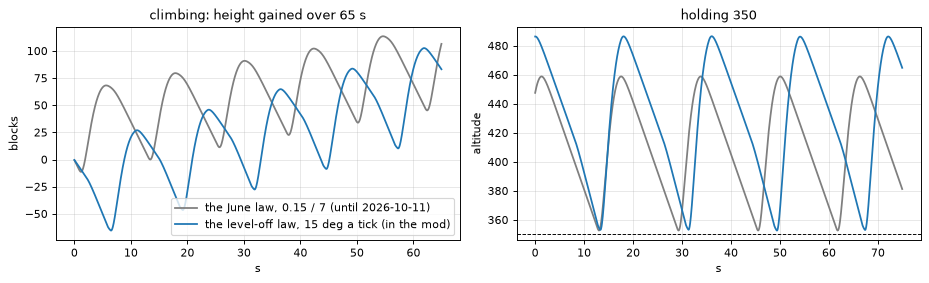

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for law, color in ((kf.JUNE, "tab:gray"), (kf.CURRENT, "tab:blue")):
    s = kf.start(law, 1e9, 0.0)
    for _ in range(3000): kf.step_look(s, 0.0)
    y0, z0, xs, ys = s.y, s.z, [], []
    for t in range(1300):
        kf.step_look(s, 0.0); xs.append(t / 20); ys.append(s.y - y0)
    axes[0].plot(xs, ys, color=color, label=law.name)
    s = kf.start(law, 350.0, 350.0)
    for _ in range(6000): kf.step_look(s, 0.0)
    zs, ys = [], []
    for t in range(1500):
        kf.step_look(s, 0.0); zs.append(t / 20); ys.append(s.y)
    axes[1].plot(zs, ys, color=color, label=law.name)
axes[0].set_title("climbing: height gained over 65 s"); axes[0].set_xlabel("s"); axes[0].set_ylabel("blocks")
axes[1].axhline(350, color="k", lw=0.8, ls="--"); axes[1].set_title("holding 350")
axes[1].set_xlabel("s"); axes[1].set_ylabel("altitude")
axes[0].legend(); plt.tight_layout(); plt.show()

In the game, in lockstep client tests (client and server ticking together, so no network timing), the new law climbed
+1.48 m/s against the model's +1.489, and cruised 31.56 m/s over three whole cycles against the model's 32.41; the old
law gave +0.92 (model +0.924) and 29.72 (model 30.12). The hold's peak is now 137 above the target, so the porpoise
sweeps a band about 134 blocks tall at cruise (June's: 106).

## 6. Why levelling off works: the energy budget

One steady climb cycle, split into the physics terms of section 2 and booked by phase (the study's `Budget`):
- **bottom**: from the pull-up trigger until the sink is gone;
- **zoom**: while climbing;
- **descent**: from the top to the next trigger.

The vertical terms are summed in m/s of vertical speed gained over the phase, the horizontal ones in m/s of forward
speed. Every tick's split is checked against `physics_step`.

In [7]:
def budget(law):
    s = kf.start(law, 1e9, 0.0)
    pulls = 0
    while pulls < 30:
        pulls += kf.step_look(s, 0.0)
    names = ("bottom", "zoom", "descent")
    acc = {n: dict(ticks=0, dy=0.0, dz=0.0, G=0.0, R=0.0, P=0.0, D=0.0, hR=0.0, hP=0.0, hS=0.0, hD=0.0) for n in names}
    acc["bottom"]["in"] = s.h_speed
    ph = 0
    while True:
        pitch = law.response.ease(s.pitch, s.cmd)
        vy, vh = s.vy, s.vz
        pr = math.radians(pitch); cp = math.cos(pr); lift = cp * cp; move = abs(vh)
        t = dict(G=0.08 * (-1 + 0.75 * lift), R=0.0, P=0.0, D=0.0, hR=0.0, hP=0.0, hS=0.0, hD=0.0)
        vy += t["G"]
        if vy < 0 and cp > 0:
            c = vy * -0.1 * lift; vh += c; vy += c; t["R"] = c; t["hR"] = c
        if pr < 0 and cp > 0:
            c = move * -math.sin(pr) * 0.04; vh -= c; vy += 3.2 * c; t["P"] = 3.2 * c; t["hP"] = -c
        if cp > 0:
            c = (move - vh) * 0.1; vh += c; t["hS"] = c
        t["hD"] = vh * 0.99 - vh; t["D"] = vy * 0.98 - vy; vh *= 0.99; vy *= 0.98
        y0, z0 = s.y, s.z
        pulled = kf.step_look(s, 0.0)
        assert abs(vh - s.vz) < 1e-12 and abs(vy - s.vy) < 1e-12
        a = acc[names[ph]]
        a["ticks"] += 1; a["dy"] += s.y - y0; a["dz"] += s.z - z0
        for k in t: a[k] += t[k] * 20
        if pulled:
            a["out"] = s.h_speed; break
        if ph == 0 and s.vy >= 0:
            a["out"] = s.h_speed; ph = 1; acc["zoom"]["in"] = s.h_speed
        elif ph == 1 and s.vy < 0:
            a["out"] = s.h_speed; ph = 2; acc["descent"]["in"] = s.h_speed
    return acc

for law in (kf.JUNE, kf.CURRENT):
    acc = budget(law)
    total = sum(a["dy"] for a in acc.values()); ticks = sum(a["ticks"] for a in acc.values())
    print(f"{law.name}: {total:+.2f} blocks a {ticks}-tick cycle ({total / ticks * 20:+.3f} m/s)")
    print("  phase    ticks  height  speed in -> out | vertical: gravity-lift  redirect   pump   drag | forward: redirect  pump  steer  drag")
    for n, a in acc.items():
        print(f"  {n:8s} {a['ticks']:5d} {a['dy']:+7.1f}   {a['in']:5.1f} -> {a['out']:5.1f}  |"
              f"        {a['G']:+7.1f}  {a['R']:+7.1f} {a['P']:+7.1f} {a['D']:+6.1f} |"
              f"          {a['hR']:+6.1f} {a['hP']:+6.1f} {a['hS']:+6.1f} {a['hD']:+6.1f}")
    print()

the June law, 0.15 / 7 (until 2026-10-11): +11.32 blocks a 245-tick cycle (+0.924 m/s)
  phase    ticks  height  speed in -> out | vertical: gravity-lift  redirect   pump   drag | forward: redirect  pump  steer  drag
  bottom      10    -3.3    44.1 ->  43.8  |           -5.4     +7.2    +7.8   +1.3 |            +7.2   -2.4   -0.5   -4.6
  zoom        89   +79.6    43.8 ->   4.5  |          -64.0     +0.0   +96.0  -32.5 |            +0.0  -30.0   +3.0  -12.3
  descent    146   -65.0     4.5 ->  44.1  |         -122.5    +85.3    +0.0  +26.5 |           +85.3   +0.0   -8.5  -37.2

the level-off law, 15 deg a tick (in the mod): +18.91 blocks a 254-tick cycle (+1.489 m/s)
  phase    ticks  height  speed in -> out | vertical: gravity-lift  redirect   pump   drag | forward: redirect  pump  steer  drag
  bottom      16    -5.3    44.2 ->  45.1  |           -7.7    +12.3    +8.9   +2.2 |           +12.3   -2.8   -0.9   -7.6
  zoom        92   +92.2    45.1 ->   4.2  |          -66.5     +0.0 

At the trigger the aircraft does about 44 m/s and sinks about 12 m/s. The sink can be stopped two ways: by the
redirect, which turns it into forward speed, or by the pump, which pays for climb with forward speed. The zoom's height
comes from the pump, and the pump grows with forward speed, so the best order is redirect first, then pump.

- **June's law** commanded a step to its pull-up pitch and let the 7-a-tick lag shape the rotation. The nose swept
  through level, so a few ticks passed at shallow pitches where the redirect works (about +7 m/s of forward speed).
  June's tuning saw this as "the lag dwells the nose on productive angles".
- **The same step under a faster response** snaps the nose past level while still sinking: the redirect almost stops
  and the pump has to cancel the sink out of forward speed, so the zoom starts slower and climbs less. That is why
  June found every faster response worse: no setting of a step law's five numbers says "level off first".
- **The level-off law** does on purpose what the lag did by accident: level for 13 ticks (the redirect wins about
  12 m/s), then a hard pull-up into the zoom at about 45 m/s. With the nose able to move 15 a tick it is level within 3
  ticks of the trigger and nearly 80 degrees up within 6 ticks of the pull-up, so the pump works at a steep angle while
  the aircraft is fastest.

## 7. The study that found it

The question (2026-10-11): would a faster autopilot pitch make the porpoise more efficient? June had found the
opposite. The study re-optimised the porpoise for each of a range of pitch responses, by differential evolution on
the mod's own flight model, for three law shapes:

- **June's shape re-tuned**: its five numbers per profile searched afresh for each response;
- **the level-off law**: level, pull-up, easing return, glide, dive (11 numbers, section 4's shape), found by looking
  at what the free-form search drew;
- **free-form**: the command after the pull-up drawn as any curve through 24 points (27 for the hold), searched freely;
  an upper bound for what any shape can do with that response.

Each was run with 3 seeds; the climb with every cycle a climb cycle, the cruise in the closed loop at 350 with the
hold's DESC_MARGIN re-centred so the mean trough sits 2.8 above the target, as June's law kept it. The study's own
simulator was in Java on the mod's classes; every result is in `fastpitch_study.csv`, and every one re-flies in
Python to the printed precision, except 4 of 493 (June's shape holding at 60 or more degrees a tick and instant,
re-flown here from a rounded climb profile, up to 0.4 m/s apart).

In [8]:
study = [r for r in csv.DictReader(open("fastpitch_study.csv"))]
print(len(study), "runs;", ", ".join(f"{f}: {sum(r['file'] == f for r in study)}" for f in sorted({r['file'] for r in study})))

def best(file, mode, resp, key):
    rs = [r for r in study if r["file"] == file and r["mode"] == mode and r["response"] == resp and r["ok"] == "true"]
    return max(rs, key=lambda r: float(r[key])) if rs else None

ORDER = ["s0.15c7", "s0.3c7", "s0.5c7", "s1c3", "s1c4", "s1c5", "s1c6", "s1c7", "s1c8", "s1c10", "s1c15", "s1c20",
         "s1c30", "s1c45", "s1c60", "s1c90", "s1cinf", "s0.15c15"]
present = [r for r in ORDER if best("opt_climbshaped.txt", "climbshaped", r, "climb")]

def resp_of(name):
    sm, cp = name[1:].split("c")
    return kf.Response(float(sm), 180.0 if cp == "inf" else float(cp))

def label(name):
    r = resp_of(name)
    return "instant" if r.cap >= 180 else (f"{r.cap:g} a tick" if r.smooth == 1 else f"{r.smooth:g} / {r.cap:g}")

def cell(file, mode, resp, hold):
    r = best(file, mode, resp, "speed" if hold else "climb")
    if r is None: return "", math.nan
    v = float(r["speed"] if hold else r["climb"])
    return (f"{v:.2f}" if hold else f"{v:+.3f}"), v

table = []
print(f"\n{'response':>12s} | {'June shape as is':>17s} | {'June re-tuned':>15s} | {'level-off':>15s} | {'free-form':>15s}")
print(f"{'':>12s} | {'climb  cruise':>17s} | {'climb  cruise':>15s} | {'climb  cruise':>15s} | {'climb  cruise':>15s}")
for name in present:
    law = kf.Law(kf.JUNE_CLIMB, kf.JUNE_HOLD, kf.JUNE_MARGIN, resp_of(name))
    c, h = kf.climb_measure(law), kf.hold_measure(law)
    holds = abs(h["climb"]) < 0.01 and h["climb_frac"] < 0.5      # held the altitude, mostly in hold cycles
    asis = (c["climb"], h["speed"] if holds else math.nan)
    rt = (cell("opt_climb.txt", "climb", name, False), cell("opt_hold.txt", "hold", name, True))
    lo = (cell("opt_climbshaped.txt", "climbshaped", name, False), cell("opt_holdshaped.txt", "holdshaped", name, True))
    ff = (cell("opt_climbsched.txt", "climbsched", name, False), cell("opt_holdsched.txt", "holdsched", name, True))
    table.append((name, asis, rt, lo, ff))
    a = f"{asis[0]:+.3f} " + (f"{asis[1]:6.2f}" if not math.isnan(asis[1]) else "can't hold")
    print(f"{label(name):>12s} | {a:>17s} | {rt[0][0]:>7s} {rt[1][0]:>7s} | {lo[0][0]:>7s} {lo[1][0]:>7s} | {ff[0][0]:>7s} {ff[1][0]:>7s}")

493 runs; opt_ablate.txt: 24, opt_climb.txt: 118, opt_climbsched.txt: 53, opt_climbshaped.txt: 63, opt_frontier.txt: 56, opt_hold.txt: 108, opt_holdsched.txt: 8, opt_holdshaped.txt: 63

    response |  June shape as is |   June re-tuned |       level-off |       free-form
             |     climb  cruise |   climb  cruise |   climb  cruise |   climb  cruise
    0.15 / 7 |     +0.924  30.12 |  +0.945   30.28 |  +1.324   31.78 |  +1.339   32.14


     0.3 / 7 |     +0.995  30.32 |  +1.044   30.44 |  +1.341   31.87 |                
     0.5 / 7 |     +1.003  30.33 |  +1.063   30.47 |  +1.346   31.90 |                
    3 a tick |     +0.304  25.51 |  +0.835         |  +0.908   30.22 |  +0.922        
    4 a tick |     +0.751  28.84 |  +0.996         |  +1.103   31.01 |  +1.096        


    5 a tick |     +0.923  29.77 |  +1.058         |  +1.222   31.42 |  +1.204        
    6 a tick |     +0.990  30.17 |  +1.077         |  +1.294   31.72 |  +1.275        


    7 a tick |     +1.002  30.31 |  +1.070   30.48 |  +1.348   31.90 |  +1.327   32.14
   10 a tick |     +0.932  30.27 |  +1.012   30.38 |  +1.436   32.21 |  +1.422        


   15 a tick |     +0.732  29.81 |  +0.883   29.95 |  +1.489   32.41 |  +1.478        
   20 a tick |     +0.551  29.28 |  +0.784   29.51 |  +1.496   32.46 |  +1.486   32.72
   30 a tick |     +0.312  28.35 |  +0.655   28.83 |  +1.478   32.45 |  +1.483   32.77
   45 a tick | +0.094 can't hold |  +0.561   28.10 |  +1.445   32.37 |  +1.484        


   60 a tick | +0.002 can't hold |  +0.532   27.97 |  +1.402   32.26 |  +1.485        


   90 a tick | -0.203 can't hold |  +0.423   27.08 |  +1.389   32.18 |  +1.240        
     instant | -0.303 can't hold |  +0.423   27.08 |  +1.389   32.18 |  +1.239        


   0.15 / 15 |     +0.750  29.50 |  +0.857   29.78 |  +1.410   32.10 |  +1.421        


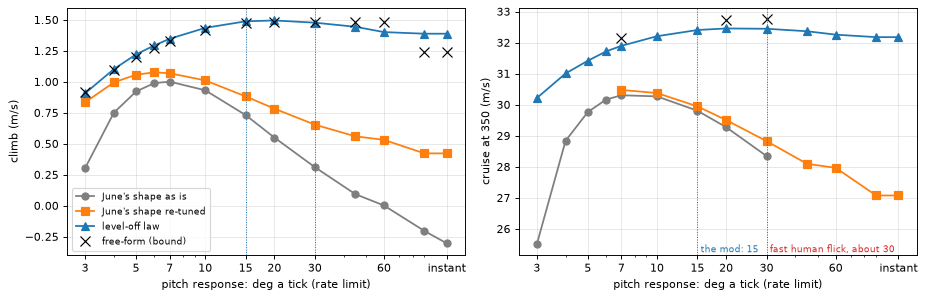

In [9]:
rate = [t for t in table if t[0].startswith("s1c")]
caps = [180.0 if t[0] == "s1cinf" else float(t[0][3:]) for t in rate]
xpos = [min(c, 90.0) * (1.0 if c < 180 else 1.25) for c in caps]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (ax, what) in enumerate(zip(axes, ("climb (m/s)", "cruise at 350 (m/s)"))):
    ax.plot(xpos, [t[1][k] for t in rate], "o-", color="tab:gray", label="June's shape as is")
    ax.plot(xpos, [t[2][k][1] for t in rate], "s-", color="tab:orange", label="June's shape re-tuned")
    ax.plot(xpos, [t[3][k][1] for t in rate], "^-", color="tab:blue", label="level-off law")
    ff = [(x, t[4][k][1]) for x, t in zip(xpos, rate) if not math.isnan(t[4][k][1])]
    ax.plot([a for a, _ in ff], [b for _, b in ff], "x", color="k", ms=8, label="free-form (bound)")
    ax.axvline(15, color="tab:blue", lw=0.8, ls=":"); ax.axvline(30, color="tab:red", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xticks([3, 5, 7, 10, 15, 20, 30, 60, 112.5]); ax.set_xticklabels(["3", "5", "7", "10", "15", "20", "30", "60", "instant"])
    ax.set_xlabel("pitch response: deg a tick (rate limit)"); ax.set_ylabel(what)
axes[0].legend(fontsize=8); axes[0].set_ylim(-0.4, 1.6)
axes[1].text(15.5, axes[1].get_ylim()[0] + 0.1, "the mod: 15", color="tab:blue", fontsize=8)
axes[1].text(31, axes[1].get_ylim()[0] + 0.1, "fast human flick, about 30", color="tab:red", fontsize=8)
plt.tight_layout(); plt.show()

What the table says:
1. **With June's shape, faster is worse**, as June found: re-tuned, the climb falls from about +1.07 m/s at 7 a tick
   to +0.78 at 20 and +0.42 instant. Unchanged, June's profiles cannot hold altitude at all with an instant response.
2. **The shape is the limit, not the speed.** The level-off law climbs about 43% faster than June's at June's own
   response (0.15 / 7).
3. **With the level-off shape, a faster response helps, up to 15 to 20 a tick**, then nothing more: the free-form bound
   at 30 to 60 is no higher. The mod flies 15, within 0.5% of 20 at three quarters of the rate, and under the human
   ceiling.
4. **Below about 7 a tick the level-off law loses again**: the nose cannot get to level and back in time.
5. Above 60 a tick the free-form search stopped converging (its seeds disagree), so its 90 and instant rows are not a
   bound; a faster response can fly anything a slower one can, so their true bound is at least the one at 60.

Rerunning the search: the level-off climb at 15 a tick, the same bounds, seed point and scheme (rand/1/bin, F dithered
between 0.5 and 0.8, crossover 0.9), via scipy, 44 points for 250 generations. Then the hold with the mod's CLIMB
profile fixed. Differential evolution is random; this run need not land on the study's numbers to the last digit.

In [10]:
from scipy.optimize import differential_evolution

def search(fun, lo, hi, seed_point, args, gens=250, pop=44, seed=1):
    lo, hi = np.array(lo, float), np.array(hi, float)
    rng = np.random.default_rng(seed)
    init = lo + rng.random((pop, len(lo))) * (hi - lo)
    init[0] = seed_point
    t = time.time()
    r = differential_evolution(fun, list(zip(lo, hi)), args=args, strategy="rand1bin", mutation=(0.5, 0.8),
                               recombination=0.9, maxiter=gens, init=init, seed=seed, workers=8,
                               updating="deferred", polish=False, tol=0)
    return r, time.time() - t

r, secs = search(kf.neg_climb, kf.SHAPED_LO_CLIMB, kf.SHAPED_HI_CLIMB, kf.SHAPED_SEED_CLIMB, (1.0, 15.0))
found_climb = kf.shaped(r.x)
print(f"climb search: {-r.fun:+.4f} m/s after {r.nfev} flights, {secs:.0f} s")
print("  found:  ", show(found_climb))
print("  the mod:", show(kf.CLIMB))
print(f"  the study's best at 15 a tick: {float(best('opt_climbshaped.txt', 'climbshaped', 's1c15', 'climb')['climb']):+.3f}; "
      f"the mod's rounded profile: {kf.climb_measure(kf.CURRENT)['climb']:+.3f}")

r, secs = search(kf.neg_cruise, kf.SHAPED_LO_HOLD, kf.SHAPED_HI_HOLD, kf.SHAPED_SEED_HOLD, (1.0, 15.0, kf.CLIMB))
found_hold = kf.shaped(r.x, hold=True)

def recenter(climb, hold, margin, resp):
    # OptFP.recenter: move DESC_MARGIN so the mean trough sits 2.8 above the target, as June's law kept it; the
    # physics doesn't depend on altitude, so the speed must not change (kept only within 0.02 m/s)
    m, best_margin = kf.hold_measure(kf.Law(climb, hold, margin, resp)), margin
    for _ in range(3):
        if not m["ok"]: break
        m2 = best_margin - (m["trough"] - 2.8)
        mm = kf.hold_measure(kf.Law(climb, hold, m2, resp))
        if not mm["ok"] or abs(mm["speed"] - m["speed"]) > 0.02 or mm["min_trough"] <= 0: break
        best_margin, m = m2, mm
        if abs(mm["trough"] - 2.8) < 0.05: break
    return best_margin, m

margin, h = recenter(kf.CLIMB, found_hold, r.x[1], kf.PORPOISE_RESPONSE)
print(f"\nhold search: {h['speed']:.2f} m/s after {r.nfev} flights, {secs:.0f} s; margin {r.x[1]:.2f} re-centred to {margin:.2f} "
      f"(trough {h['trough']:+.2f})")
print("  found:  ", show(found_hold))
print("  the mod:", show(kf.ALT_HOLD), f"(margin {kf.DESC_MARGIN})")

climb search: +1.4889 m/s after 11044 flights, 21 s
  found:   dive 44.3 down, pull up at 43.8 m/s; 0.1 down for 13 ticks; 78.9 up for 3; ease 0.0343 of the gap toward 7.1 up for 86; glide 32.8 down for 80
  the mod: dive 44.3 down, pull up at 44.1 m/s; level for 13 ticks; 78.5 up for 3; ease 0.0336 of the gap toward 6.9 up for 86; glide 32.9 down for 81
  the study's best at 15 a tick: +1.489; the mod's rounded profile: +1.489



hold search: 32.40 m/s after 11044 flights, 40 s; margin 21.62 re-centred to 8.69 (trough +2.81)
  found:   dive 44.8 down, pull up on altitude; 0.4 down for 13 ticks; 82.2 up for 1; ease 0.0231 of the gap toward 9.1 down for 85; glide 37.6 down for 176
  the mod: dive 44.5 down, pull up on altitude; 0.1 down for 13 ticks; 82.7 up for 1; ease 0.0219 of the gap toward 12.6 down for 84; glide 37.6 down for 173 (margin 8.7)


Both searches land on the same shape as the study: level for 13 ticks, a pull-up to about 80 degrees for a few ticks,
an easing return over about 85 ticks, a shallow glide, the dive at 44. Under a rate limit the pull-up pitch and its
hold trade against each other (the nose only gets so far in a few ticks), so seeds differ there with equal results.

**Which parts matter** (the study's ablations): the level phase switched off, or the glide, everything else
re-optimised.

In [11]:
print(f"{'response':>10s}  {'full law':>10s}  {'no level':>10s}  {'no glide':>10s}   (climb m/s; cruise m/s)")
for name in ("s1c7", "s1c20", "s1c30"):
    out = []
    for hold, key in ((False, "climb"), (True, "speed")):
        base = "holdshaped" if hold else "climbshaped"
        full = best("opt_" + base + ".txt", base, name, key)
        nl = best("opt_ablate.txt", base + "-nolevel", name, key)
        ng = best("opt_ablate.txt", base + "-noglide", name, key)
        fmt = (lambda r: f"{float(r[key]):.2f}") if hold else (lambda r: f"{float(r[key]):+.3f}")
        out.append(" ".join(f"{(fmt(r) if r else '-'):>10s}" for r in (full, nl, ng)))
    print(f"{label(name):>10s}  {out[0]}   ; {out[1]}")

  response    full law    no level    no glide   (climb m/s; cruise m/s)
  7 a tick      +1.348     +1.164     +1.190   ;      31.90      31.25      31.40
 20 a tick      +1.496     +0.849     +1.337   ;      32.46      31.59      31.97
 30 a tick      +1.478     +0.699     +1.330   ;      32.45      31.48      31.97


Without the level phase a faster response is worse again (climb +1.16 at 7 a tick, +0.85 at 20, +0.70 at 30): the
level phase is what lets the speed pay. The glide adds less (at 20 a tick, +1.34 without it against +1.50).

**The climbing frontier**: the best climb at a required ground speed. At 20 a tick the level-off law climbs at 28 m/s
about as well as June's re-tuned law climbs at 22.

In [12]:
fr = [r for r in study if r["file"] == "opt_frontier.txt" and r["ok"] == "true"]
speeds = sorted({float(r["min_speed"]) for r in fr})
print(f"{'law, response':34s}" + "".join(f"{s:>9.0f}" for s in speeds) + "   (m/s ground)")
for mode, name in (("climb", "s0.15c7"), ("climbshaped", "s0.15c7"), ("climbshaped", "s1c20")):
    row = []
    for sp in speeds:
        rs = [r for r in fr if r["mode"] == mode and r["response"] == name and float(r["min_speed"]) == sp]
        row.append(f"{max(float(r['climb']) for r in rs):+9.3f}" if rs else f"{'':>9s}")
    lab = ("June re-tuned" if mode == "climb" else "level-off") + ", " + label(name)
    print(f"{lab:34s}" + "".join(row))

law, response                            22       24       26       28       29       30   (m/s ground)
June re-tuned, 0.15 / 7              +0.944   +0.876   +0.701   +0.426   +0.253         
level-off, 0.15 / 7                           +1.277   +1.100   +0.807            +0.402
level-off, 20 a tick                          +1.456   +1.283   +0.990            +0.585


**The free-form search drew the level-off law.** Free to put the command anywhere at 24 points after the pull-up, its
best climb at 20 a tick holds level for 10 to 15 ticks, pulls hard to 70 to 88 degrees up, eases back, glides, then
dives. The level-off law is that drawing with 11 numbers, within about 1% of it in the climb.

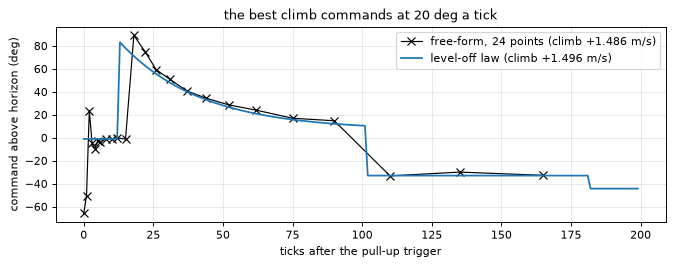

In [13]:
TAU = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 22, 26, 31, 37, 44, 52, 62, 75, 90, 110, 135, 165]
r = best("opt_climbsched.txt", "climbsched", "s1c20", "climb")
knots = [float(v) for v in r["profile"].split(";")[1].strip(" )").split()]
lev = best("opt_climbshaped.txt", "climbshaped", "s1c20", "climb")
p = kf.shaped([float(v) for v in lev["x"].split()])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(TAU, [-k for k in knots], "kx-", lw=1, label=f"free-form, 24 points (climb {float(r['climb']):+.3f} m/s)")
cmds = [p.cmd_at(t) for t in range(0, 200)]
ax.plot(range(200), [-(c if not math.isnan(c) else p.dive) for c in cmds], color="tab:blue",
        label=f"level-off law (climb {float(lev['climb']):+.3f} m/s)")
ax.set_xlabel("ticks after the pull-up trigger"); ax.set_ylabel("command above horizon (deg)")
ax.set_title("the best climb commands at 20 deg a tick"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Disturbances: a frozen second, a lag spike

The study's robustness test, run on the mod's law: the pitch held still for 20 ticks (a 1 s freeze of the controls)
or 10 ticks (a lag spike: a frame runs at most 10 ticks, `Minecraft.java:1298`) while the ticks and the law keep
running, begun at 40 points spread over one cycle. In the hold: the lowest point after the event against the target.
In the climb: the height the event cost, read off the pull-up altitudes after it against the undisturbed climb's line.
(The study also flew a catch-up after a stalled frame; since the autopilot now steps its command once a tick, that no
longer applies.)

In [14]:
def steady(law, hold):
    s = kf.start(law, 350.0 if hold else 1e9, 350.0 if hold else 0.0)
    pulls = 0
    while pulls < 25:
        pulls += kf.step_look(s, 0.0)
    return s

def period(s0):
    s, t = s0.copy(), 0
    while True:
        t += 1
        if kf.step_look(s, 0.0) or t >= 5000:
            return t

def fly(s, ticks, at=0, length=0):
    ys, pulls = [], []
    for t in range(ticks):
        pulls.append(kf.step_look(s, 0.0, frozen=length > 0 and at <= t < at + length))
        ys.append(s.y)
    return ys, pulls

print(f"{'':44s}{'1 s freeze':>14s}{'10-tick spike':>16s}")
for law in (kf.JUNE, kf.CURRENT):
    base = steady(law, True); per = period(base)
    out = []
    for length in (20, 10):
        worst = min(min(fly(base.copy(), 8000, 300 + round(i * per / 40), length)[0][300:]) for i in range(40))
        out.append(worst - 350)
    print(f"{law.name:44s}{out[0]:+14.1f}{out[1]:+16.1f}   lowest point in the hold (target 0)")
    cb = steady(law, False); cper = period(cb)
    ys0, p0 = fly(cb.copy(), 4000)
    pts = [(t, ys0[t]) for t in range(4000) if p0[t]]
    slope, icpt = np.polyfit([t for t, _ in pts], [y for _, y in pts], 1)
    out = []
    for length in (20, 10):
        worst = 0.0
        for i in range(40):
            at = 300 + round(i * cper / 40)
            ys, pl = fly(cb.copy(), 4000, at, length)
            after = [t for t in range(at, 4000) if pl[t]][2:6]
            worst = max(worst, sum(icpt + slope * t - ys[t] for t in after) / len(after))
        out.append(worst)
    print(f"{'':44s}{out[0]:>9.0f} ({out[0] / (slope * 20):.0f} s){out[1]:>10.0f} ({out[1] / (slope * 20):.0f} s)   height lost climbing (seconds of climb)")

                                                1 s freeze   10-tick spike


the June law, 0.15 / 7 (until 2026-10-11)             -6.5            -1.6   lowest point in the hold (target 0)
                                                   21 (23 s)         5 (5 s)   height lost climbing (seconds of climb)


the level-off law, 15 deg a tick (in the mod)          -2.8            +1.1   lowest point in the hold (target 0)


                                                   26 (18 s)        14 (9 s)   height lost climbing (seconds of climb)


The hold comes through both better than June's law; the climb loses a little more to a lag spike (a spike in the
level phase or the pull-up throws off the pull-up's timing) but nothing ever gets stuck in a dive.

## 9. What other code takes from the porpoise

Numbers elsewhere in the mod that depend on the law (the study's `Deps`), checked against today's law.

In [15]:
c, h = res[kf.CURRENT.name]
cj, hj = res[kf.JUNE.name]
rows = [
    ("climb cycle, ticks (AltitudeLaw PERIOD_MIN 160, PERIOD_MAX 420)", f"{cj['period']:.0f}", f"{c['period']:.0f}"),
    ("hold cycle, ticks; 4 of them (RangeEndurance SPEED_WINDOW 1500)", f"{hj['period']:.0f}; {4 * hj['period']:.0f}", f"{h['period']:.0f}; {4 * h['period']:.0f}"),
    ("model speeds, climb / hold (AltitudeLaw CLIMB_SPEED 22.5, HOLD_SPEED 32.4)", f"{cj['speed']:.1f} / {hj['speed']:.1f}", f"{c['speed']:.1f} / {h['speed']:.1f}"),
    ("hold peak above the target (AltitudeLaw DESC_LIVE 150)", f"{hj['peak']:+.0f}", f"{h['peak']:+.0f}"),
    ("climb gradient (TurnPlanner CLIMB_GRAD 0.05 assumes less)", f"{cj['climb'] / cj['speed']:.3f}", f"{c['climb'] / c['speed']:.3f}"),
    ("pitch flown climbing, up / down (deg)", f"{-cj['pitch_min']:.0f} / {cj['pitch_max']:.0f}", f"{-c['pitch_min']:.0f} / {c['pitch_max']:.0f}"),
    ("fastest pitch change (deg a tick)", f"{cj['max_rate']:.1f}", f"{c['max_rate']:.1f}"),
]
def first_dive(law, v):
    s = kf.State(0, 0, 0, 0, 0, v / 20, 1e9, 0, True, law); s.restart_climb()
    low, pulls = 0.0, 0
    for _ in range(4000):
        p = kf.step_look(s, 0.0); low = min(low, s.y)
        if p:
            pulls += 1
            if pulls == 2: break
    return -low
rows.append(("first dive after arming from level at 20 (5) m/s: depth", f"{first_dive(kf.JUNE, 20):.0f} ({first_dive(kf.JUNE, 5):.0f})",
             f"{first_dive(kf.CURRENT, 20):.0f} ({first_dive(kf.CURRENT, 5):.0f})"))
print(f"{'':76s}{'June':>12s}{'now':>12s}")
for a, b, n in rows:
    print(f"{a:76s}{b:>12s}{n:>12s}")

                                                                                    June         now
climb cycle, ticks (AltitudeLaw PERIOD_MIN 160, PERIOD_MAX 420)                      245         254
hold cycle, ticks; 4 of them (RangeEndurance SPEED_WINDOW 1500)                325; 1300   360; 1441
model speeds, climb / hold (AltitudeLaw CLIMB_SPEED 22.5, HOLD_SPEED 32.4)   21.9 / 30.1 22.5 / 32.4
hold peak above the target (AltitudeLaw DESC_LIVE 150)                              +109        +137
climb gradient (TurnPlanner CLIMB_GRAD 0.05 assumes less)                          0.042       0.066
pitch flown climbing, up / down (deg)                                            52 / 40     74 / 44
fastest pitch change (deg a tick)                                                    7.0        15.0
first dive after arming from level at 20 (5) m/s: depth                          55 (69)     61 (78)


The terrain planner's rollouts (`TurnPlanner`, `PathPrediction`, `TurnGuard.feasibleToArm`) step the same law, so they
follow it with no change; what moves is what they predict: a first dive a few blocks deeper (the arming floor on flat
ground rises with it) and a taller cruise band.

## 10. Turning

Steering moves the horizontal velocity 10% of the way toward the look's heading each tick at the same speed, so a
look held a fixed offset off the velocity turns at a rate set by the offset alone, at any speed; the radius is the
speed over that rate. Each tick the step also shortens the horizontal velocity, by about 0.07% at 7 degrees on top of
the 1% drag, 0.5% at 20 and 9% at 90, so turning costs climb. Here the look is held each offset right of the velocity
for 10 minutes, climbing (target far above) and holding 350.

In [16]:
def turning(law, offset, hold):
    # 10 minutes with the look held `offset` right of the velocity, from a steady straight cycle
    s = steady(law, hold)
    heading, last, y0 = 0.0, kf.vel_yaw(s.vx, s.vz), s.y
    ys, pulls, speeds = [], [], []
    for t in range(12000):
        pulled = kf.step_look(s, kf.vel_yaw(s.vx, s.vz) + offset)
        yaw = kf.vel_yaw(s.vx, s.vz); heading += kf.wrap180(yaw - last); last = yaw
        ys.append(s.y); speeds.append(s.h_speed)
        if pulled:
            pulls.append(t)
    rate = heading / (12000 / 20)                       # deg/s
    if len(pulls) >= 4:                                 # whole cycles after settling
        a, b = pulls[2], pulls[-1]
    else:                                               # no steady cycle: the whole run
        a, b = 0, len(ys) - 1
    climb = (ys[b] - ys[a]) / (b - a) * 20
    spd = sum(speeds[a:b]) / (b - a)
    radius = spd / math.radians(rate) if rate else math.inf
    return dict(rate=rate, climb=climb, speed=spd, radius=radius, pulls=len(pulls), lowest=min(ys) - 350)

offsets = [0, 1, 2, 3, 4, 5, 6, 7, 7.5, 8, 9, 10, 12, 15, 20]
print(f"{'offset':>6s} | {'turn':>8s} {'radius':>7s} {'climb':>8s} {'pull-ups':>9s} | {'hold: height':>13s} {'lowest point':>13s}")
turn_rows = []
for off in offsets:
    c, h = turning(kf.CURRENT, off, False), turning(kf.CURRENT, off, True)
    turn_rows.append((off, c, h))
    note = "" if c["pulls"] >= 4 else "  never reaches its pull-up speed: a spiral dive"
    print(f"{off:6.1f} | {c['rate']:6.1f}/s {c['radius']:7.0f} {c['climb']:+8.3f} {c['pulls']:9d} | "
          f"{h['climb'] * 60:+9.1f}/min {h['lowest']:+13.1f}{note}")

offset |     turn  radius    climb  pull-ups |  hold: height  lowest point
   0.0 |    0.0/s     inf   +1.489        47 |      -0.1/min          +2.7
   1.0 |    2.2/s     593   +1.473        47 |      +0.0/min          +2.6
   2.0 |    4.4/s     297   +1.423        47 |      +0.0/min          +2.6
   3.0 |    6.5/s     198   +1.340        46 |      -0.0/min          +2.6
   4.0 |    8.7/s     149   +1.223        46 |      -0.0/min          +2.6
   5.0 |   10.9/s     119   +1.072        46 |      +0.0/min          +2.7


   6.0 |   13.1/s      99   +0.886        45 |      -0.1/min          +2.7


   7.0 |   15.3/s      86   +0.662        45 |      -0.0/min          +2.7


   7.5 |   16.4/s      80   +0.540        45 |      -0.0/min          +2.7
   8.0 |   17.5/s      75   +0.403        44 |      +0.1/min          +2.7
   9.0 |   19.7/s      67   +0.101        44 |      -0.6/min         -11.5
  10.0 |   21.9/s      60   -0.245        43 |     -16.0/min        -144.3
  12.0 |   26.4/s      51   -1.113        41 |     -68.5/min        -638.5
  15.0 |   33.3/s      44   -3.068        35 |    -184.1/min       -1764.6


  20.0 |   45.1/s      50  -12.791         0 |    -737.9/min       -7369.8  never reaches its pull-up speed: a spiral dive


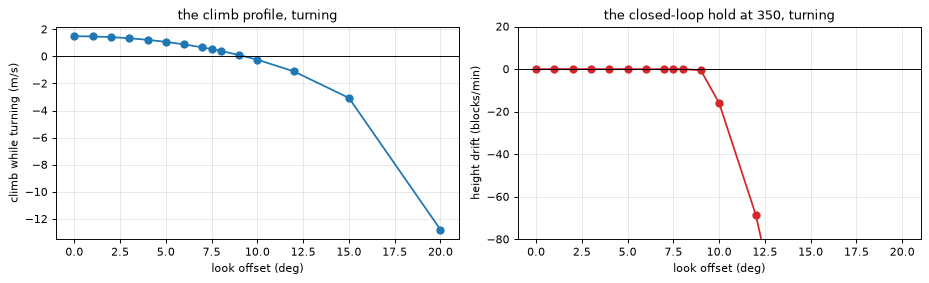

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot([r[0] for r in turn_rows], [r[1]["climb"] for r in turn_rows], "o-")
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xlabel("look offset (deg)"); axes[0].set_ylabel("climb while turning (m/s)")
axes[0].set_title("the climb profile, turning")
axes[1].plot([r[0] for r in turn_rows], [r[2]["climb"] * 60 for r in turn_rows], "o-", color="tab:red")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xlabel("look offset (deg)"); axes[1].set_ylabel("height drift (blocks/min)")
axes[1].set_title("the closed-loop hold at 350, turning"); axes[1].set_ylim(-80, 20)
plt.tight_layout(); plt.show()

The hold keeps its height turning at up to 8 degrees off the velocity; at 9 its lowest point dips about 11 below the
target, and from 10 it falls away: its climb cycles cannot win the height back while the turn goes on. The holding circle (next section) flies 7, and 5 while
the law climbs. Held at 20 degrees, the mod's steering limit (`FlightModel3D.DELTA_MAX`), the climb law never gets
back to its 44 m/s pull-up speed: the turn bleeds off the speed the dive builds, so it dives in a spiral and never
pulls up. The terrain planner's turns hold up to 20 until the heading is within 20 of where they are going; whether a
long one on the climb profile runs into this is not checked here.

## 11. The holding circle

Over a destination the autopilot can hold until day (`HoldModel`, chosen from a search of shapes on 2026-10-11): the look
held 7 degrees right of the velocity while the porpoise flies the height as usual; 2 degrees less while the velocity
points at the fix and 2 more while it points away, so the circle drifts until the fix is its centre; at most 5 degrees
while the law climbs, since turning costs climb. Flown here as `HoldModelTest` flies it: straight until the cycle is
steady, then 12 minutes on the circle, the first 6 for centring.

lowest point 352.8 (target 350); lowest trough after centring 352.8; farthest from the fix after centring 150 blocks; a lap every 23.9 s


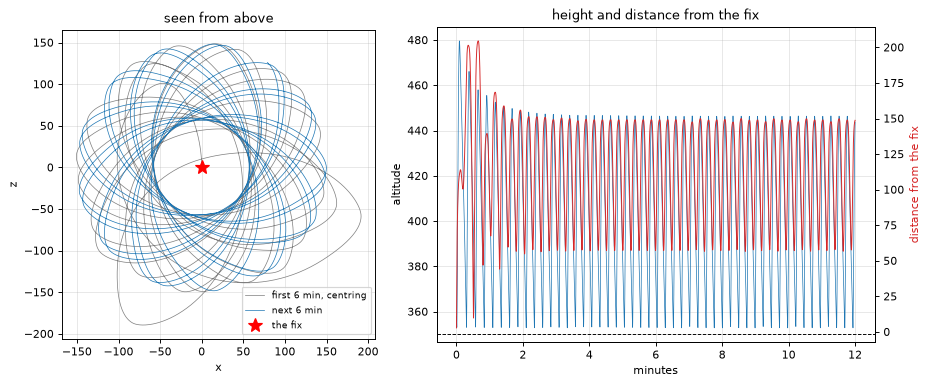

In [18]:
s = kf.State(0, 400, 0, 0, -0.3, 1.5, 350, 30, False); s.cmd = kf.ALT_HOLD.dive
pulls = 0
while pulls < 12:
    ph = s.phase; kf.step(s, 0.0); pulls += ph == kf.DIVE and s.phase != kf.DIVE
s.x = s.z = 0.0
xs, zs, ys, dist = [], [], [], []
heading, last = 0.0, kf.vel_yaw(s.vx, s.vz)
lowest, troughs = math.inf, []
for t in range(14400):
    ph = s.phase
    kf.step_look(s, kf.hold_look_yaw(s.x, s.z, 0, 0, kf.vel_yaw(s.vx, s.vz), s.climbing))
    yaw = kf.vel_yaw(s.vx, s.vz)
    if t >= 7200: heading += kf.wrap180(yaw - last)
    last = yaw
    xs.append(s.x); zs.append(s.z); ys.append(s.y); dist.append(math.hypot(s.x, s.z))
    lowest = min(lowest, s.y)
    if t >= 7200 and ph == kf.DIVE and s.phase != kf.DIVE: troughs.append(s.trough)
print(f"lowest point {lowest:.1f} (target 350); lowest trough after centring {min(troughs):.1f}; "
      f"farthest from the fix after centring {max(dist[7200:]):.0f} blocks; "
      f"a lap every {360 / (abs(heading) / (7200 / 20)):.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(xs[:7200], zs[:7200], color="tab:gray", lw=0.6, label="first 6 min, centring")
axes[0].plot(xs[7200:], zs[7200:], color="tab:blue", lw=0.6, label="next 6 min")
axes[0].plot(0, 0, "r*", ms=12, label="the fix"); axes[0].set_aspect("equal")
axes[0].set_xlabel("x"); axes[0].set_ylabel("z"); axes[0].legend(fontsize=8); axes[0].set_title("seen from above")
tt = [t / 20 / 60 for t in range(14400)]
axes[1].plot(tt, ys, lw=0.6); axes[1].axhline(350, color="k", ls="--", lw=0.8)
ax2 = axes[1].twinx(); ax2.plot(tt, dist, color="tab:red", lw=0.8); ax2.set_ylabel("distance from the fix", color="tab:red"); ax2.grid(False)
axes[1].set_xlabel("minutes"); axes[1].set_ylabel("altitude"); axes[1].set_title("height and distance from the fix")
plt.tight_layout(); plt.show()

The circle was chosen on June's law, where it stayed within about 121 blocks of the fix; today's faster cruise widens
it (the turn rate is set by the offset, so the radius grows with speed), and `HoldModelTest` now allows 160. Each lap
is an egg, tight at the slow top of the zoom and wide at the fast bottom, and a lap is not a whole number of porpoise
cycles, so the egg turns a little each lap and fills a disc.

## 12. The aimed landing

`LandingModel`, flown on its own pitch response (0.15 / 7), five phases:
- **approach**: glide 5 degrees down toward the spot until 8 blocks out;
- **spiral plunge**: a radius-2 spiral round the spot at 60 degrees down, about 28 m/s, nearly vertical;
- **brake**: from 60 above the spot, nose up 30 with the look on the spot, until sinking slower than 0.35 blocks a tick;
- **middle spiral**: the spiral again at 25 degrees down, about 5.5 m/s down, to 10 above;
- **finish**: nose up 5 with the look on the spot, about 3 m/s down, drifting onto it.

Tuned (on 2026-10-11) for speed under failure: a 1 s freeze of the controls anywhere costs no health, and once braked, any
frozen or bumped look touches down with no fall damage. Here: one landing from cruise, 200 blocks out.

touched down 0.82 blocks from the spot's centre after 26.1 s, fall damage 0.0
  approach         6.6 s
  spiral plunge    8.8 s
  brake            0.8 s
  middle spiral    6.8 s
  finish           3.0 s


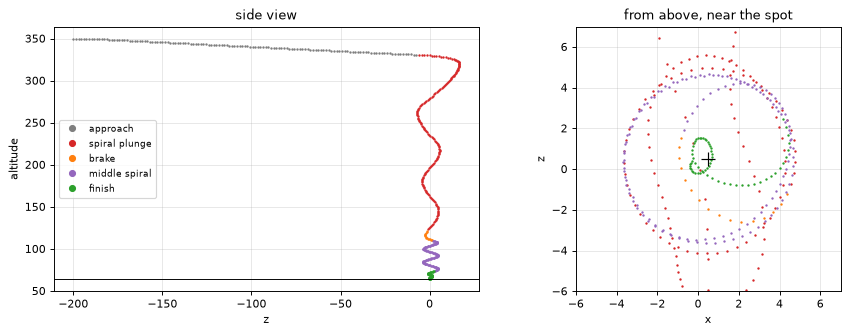

In [19]:
r = kf.landing_simulate(kf.LandingLaw(), 0.5, 350, -200, 0, 0, 1.5, 0, 10, 0.5, 64, 0.5, 4000)
print(f"touched down {r['offset']:.2f} blocks from the spot's centre after {r['ticks'] / 20:.1f} s, fall damage {r['damage']:.1f}")
for ph, name in kf.LANDING_PHASES.items():
    n = sum(1 for p in r["phases"][1:] if p == ph)
    print(f"  {name:14s} {n / 20:5.1f} s")
cols = {0: "tab:gray", 1: "tab:red", 2: "tab:orange", 3: "tab:purple", 4: "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ph, name in kf.LANDING_PHASES.items():
    idx = [i for i, p in enumerate(r["phases"]) if p == ph]
    axes[0].plot([r["zs"][i] for i in idx], [r["ys"][i] for i in idx], ".", ms=2, color=cols[ph], label=name)
    axes[1].plot([r["xs"][i] for i in idx], [r["zs"][i] for i in idx], ".", ms=2, color=cols[ph])
axes[0].axhline(64, color="k", lw=0.8); axes[0].set_xlabel("z"); axes[0].set_ylabel("altitude"); axes[0].legend(markerscale=5, fontsize=8)
axes[0].set_title("side view")
axes[1].set_xlim(-6, 7); axes[1].set_ylim(-6, 7); axes[1].set_aspect("equal"); axes[1].plot(0.5, 0.5, "k+", ms=12)
axes[1].set_title("from above, near the spot"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")
plt.tight_layout(); plt.show()

**Robustness**, as `LandingModelTest` starts them: the spot at height 0, starts at 40 to 250 up, the spot 30 to 80
degrees below the horizon, 10 to 50 m/s, facing it, across or away. Then the 1 s freeze, begun at every 4th tick of a
landing from 250 up.

The landing's unit test for the freeze (and its phase-order test) eases the pitch with `FlightModel3D.ease`, which since
2026-10-11 is the porpoise's 15 a tick; the mod flies the landing on `easeLanding`, 0.15 / 7. Both are run here.

In [20]:
def land(h, ang, speed, head, freeze=None, response=kf.LANDING_RESPONSE):
    d = h / math.tan(math.radians(ang)); yr = math.radians(-head)
    return kf.landing_simulate(kf.LandingLaw(), 0.5, h, 0.5 - d, math.sin(yr) * speed, -0.1, math.cos(yr) * speed,
                               head, 10.0, 0.5, 0.0, 0.5, 6000, freeze=freeze, response=response)

runs = [land(h, a, sp, hd) for h in (40, 80, 150, 250) for a in (30, 45, 80) for sp in (0.5, 1.5, 2.5) for hd in (0, 90, 180)]
offs = sorted(r["offset"] for r in runs)
print(f"{len(runs)} starts: all touched down {all(r['touched'] for r in runs)}; most fall damage {max(r['damage'] for r in runs):.1f}; "
      f"offset median {offs[len(offs) // 2]:.2f}, worst {offs[-1]:.2f}; time {min(r['ticks'] for r in runs) / 20:.0f} to {max(r['ticks'] for r in runs) / 20:.0f} s")
for resp, name in ((kf.LANDING_RESPONSE, "the mod's landing response, 0.15 / 7"), (kf.PORPOISE_RESPONSE, "the unit test's, 15 a tick")):
    nominal = land(250, 45, 1.5, 0, response=resp)
    worst = max(land(250, 45, 1.5, 0, freeze=(at, 20), response=resp)["damage"] for at in range(1, nominal["ticks"], 4))
    print(f"1 s freeze at every 4th tick from 250 up, {name}: most fall damage {worst:.1f}")

108 starts: all touched down True; most fall damage 0.0; offset median 0.79, worst 2.63; time 9 to 36 s
1 s freeze at every 4th tick from 250 up, the mod's landing response, 0.15 / 7: most fall damage 0.0


1 s freeze at every 4th tick from 250 up, the unit test's, 15 a tick: most fall damage 0.0


**The landing reserve.** The durability readout keeps enough elytra for a landing from the current height down to the
world's bottom; `LandingTime` is a table rolled out offline (the longest landing over the phases of a steady hold
porpoise placed at each height, the spot straight below). Below 60 the law brakes at once, and from the fast bottom of
a dive that brake zooms up before it comes down, hence the step at 60 and the bump at 1 to 10.

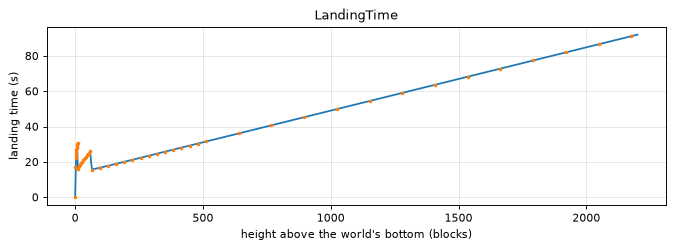

In [21]:
hs = np.linspace(0, 2200, 600)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(hs, [kf.landing_seconds(h) for h in hs])
ax.plot(kf.LANDING_TIME_HEIGHT, kf.LANDING_TIME_SECONDS, ".", ms=4)
ax.set_xlabel("height above the world's bottom (blocks)"); ax.set_ylabel("landing time (s)")
ax.set_title("LandingTime"); plt.tight_layout(); plt.show()

## 13. The rocket takeoff

**Rockets.** The server rolls each rocket's life as 10 (1 + flight duration) + nextInt(6) + nextInt(7) ticks and
pushes the attached player every tick until it ends, so a rocket burns life + 1 ticks; the client never learns the
roll. While it burns the push is v = 0.5 v + 0.85 L each tick (L the look), converging to 1.7 blocks a tick (34 m/s)
whatever the duration; stacked rockets don't raise the top speed.

In [22]:
for dur in (1, 2, 3):
    print(f"flight duration {dur}: burns {kf.rocket_min_ticks(dur)} to {kf.rocket_max_ticks(dur)} ticks, mean {kf.rocket_mean_ticks(dur):.1f} "
          f"({kf.rocket_mean_ticks(dur) / 20:.2f} s)")
print("\nsteady climb under a push, by angle above the horizon:")
for up in (90, 85, 80, 75, 70, 65, 60, 50, 45):
    v = [0.0, 0.0, 0.0]
    for _ in range(400):
        kf.physics_step(0, -up, v); climb, fwd = v[1], v[2]; kf.boost(0, -up, v)
    print(f"  {up:2d} deg: climb {climb * 20:5.1f} m/s, forward {fwd * 20:5.1f} m/s")

flight duration 1: burns 21 to 32 ticks, mean 26.5 (1.32 s)
flight duration 2: burns 31 to 42 ticks, mean 36.5 (1.82 s)
flight duration 3: burns 41 to 52 ticks, mean 46.5 (2.33 s)

steady climb under a push, by angle above the horizon:
  90 deg: climb  29.6 m/s, forward   0.0 m/s
  85 deg: climb  30.2 m/s, forward   2.7 m/s
  80 deg: climb  30.5 m/s, forward   5.4 m/s
  75 deg: climb  30.6 m/s, forward   8.1 m/s
  70 deg: climb  30.5 m/s, forward  10.7 m/s
  65 deg: climb  30.0 m/s, forward  13.2 m/s
  60 deg: climb  29.3 m/s, forward  15.7 m/s
  50 deg: climb  26.9 m/s, forward  20.3 m/s
  45 deg: climb  25.2 m/s, forward  22.4 m/s


Climbing 90 to 60 degrees above the horizon costs almost nothing in climb rate while the forward speed grows, so the
takeoff (`TakeoffModel`) climbs straight up while a leaning climb would come within 6 blocks of terrain, then leans to
70 at 120 deg/s. At the end of each rocket it fires another only if the autopilot, handed over now in altitude hold,
would fall short of the cruise. From flat ground at 64 to the 350 cruise, mean duration-1 rockets (27 ticks):

8 rockets; hand-over to the autopilot after 11.3 s at y 401, 115 blocks forward; lowest after it 352.8


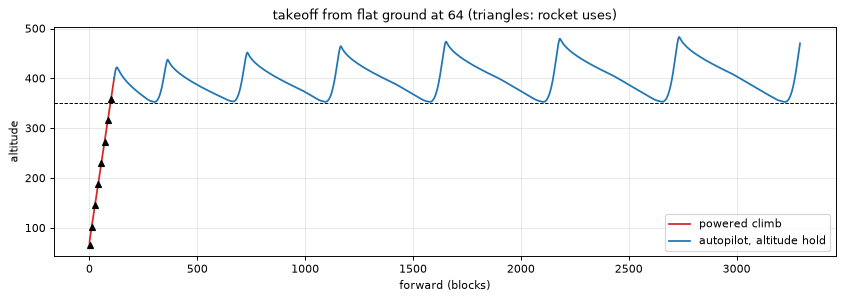


rockets to the 350 cruise, if every rocket burns its shortest (what the mod asks you to carry) / its mean:
  ground      duration 1      duration 2      duration 3


     -60        14 / 11         10 / 8           8 / 7  


       0        12 / 10          9 / 7           7 / 6  


      64        10 / 8           7 / 6           6 / 5  


     100         9 / 7           7 / 6           5 / 5  
     150         8 / 6           6 / 5           4 / 4  


     200         6 / 5           5 / 4           4 / 3  
     280         4 / 3           3 / 2           2 / 2  


In [23]:
p = kf.takeoff(0.5, 64, 0.5, 0, 350, 27, lambda x, z: 64.0, 319, 2400)
hand = p["ticks"]
print(f"{p['rockets']} rockets; hand-over to the autopilot after {hand / 20:.1f} s at y {p['ys'][hand]:.0f}, "
      f"{p['zs'][hand]:.0f} blocks forward; lowest after it {min(p['ys'][hand + 60:]):.1f}")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(p["zs"][:hand + 1], p["ys"][:hand + 1], color="tab:red", label="powered climb")
ax.plot(p["zs"][hand:], p["ys"][hand:], color="tab:blue", label="autopilot, altitude hold")
for u in p["uses"]:
    ax.plot(p["zs"][u], p["ys"][u], "k^", ms=5)
ax.axhline(350, color="k", ls="--", lw=0.8); ax.set_xlabel("forward (blocks)"); ax.set_ylabel("altitude")
ax.set_title("takeoff from flat ground at 64 (triangles: rocket uses)"); ax.legend(); plt.tight_layout(); plt.show()

print("\nrockets to the 350 cruise, if every rocket burns its shortest (what the mod asks you to carry) / its mean:")
print(f"{'ground':>8s}" + "".join(f"{'duration ' + str(d):>16s}" for d in (1, 2, 3)))
for g in (-60, 0, 64, 100, 150, 200, 280):
    row = []
    for d in (1, 2, 3):
        a = kf.takeoff(0.5, g, 0.5, 0, 350, kf.rocket_min_ticks(d), lambda x, z, g=g: g, 319, 10)
        b = kf.takeoff(0.5, g, 0.5, 0, 350, kf.jround(kf.rocket_mean_ticks(d)), lambda x, z, g=g: g, 319, 10)
        row.append(f"{a['rockets']:>10d} / {b['rockets']:<3d}")
    print(f"{g:>8d}" + "".join(f"{c:>16s}" for c in row))

## 14. Rockets that hit their own player

Found on 2026-10-11 with server-side logging in a real world: a rocket used while already flying fast can hit its own
player and burst a few ticks in, so the takeoff fired rocket after rocket. The server spawns a rocket at the player
with a speed of 0.05; if the player has moved more than about 1.4 blocks by its first tick it counts as having left
its owner (`Projectile.isOutsideOwnerCollisionRange`), and from then on its owner is a target. Each tick the attached
rocket sits at the hand (half a block from the feet, at the player's yaw plus 80 degrees for the right arm, minus 80
for the left) and traces one tick along the player's velocity against the player's 0.6 box, grown with the rocket's
age (`ProjectileUtil.computeMargin`). `AABB.clip` counts only a face the path enters, so whether it hits depends on the
heading against the world's axes. `RocketHit` is that test as a pure function; the takeoff climbs along the nearest
heading at least 3 degrees clear of every band (`RocketHit.safeYaw`).

right arm, 70 up   hits at yaws 63.2-83.5, 153.2-173.5, 243.2-263.5, 333.2-353.5
left arm, 70 up    hits at yaws 6.5-26.8, 96.5-116.8, 186.5-206.8, 276.5-296.8


right arm, 85 up   hits at yaws 63.2-67.8, 74.2-78.0, 153.2-157.8, 164.2-168.0, 243.2-247.8, 254.2-258.0, 333.2-337.8, 344.2-348.0


left arm, 85 up    hits at yaws 12.0-15.8, 22.2-26.8, 102.0-105.8, 112.2-116.8, 192.0-195.8, 202.2-206.8, 282.0-285.8, 292.2-296.8


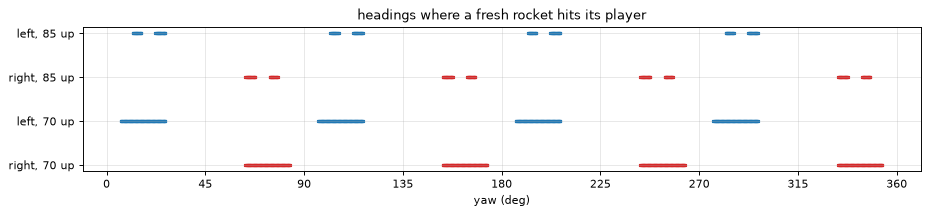

wanted heading 167: the takeoff climbs along 177.5 (right arm)
wanted heading 70: the takeoff climbs along 60.0 (right arm)
wanted heading 160: the takeoff climbs along 150.0 (right arm)
wanted heading 250: the takeoff climbs along 240.0 (right arm)


In [24]:
yaws = np.arange(0, 360, 0.25)
fig, ax = plt.subplots(figsize=(11, 2.6))
for k, (pitch, arm, name) in enumerate(((-70, True, "right arm, 70 up"), (-70, False, "left arm, 70 up"),
                                        (-85, True, "right arm, 85 up"), (-85, False, "left arm, 85 up"))):
    hit = [kf.rocket_hits(y, pitch, arm) for y in yaws]
    ax.scatter(yaws[hit], [k] * sum(hit), s=2, marker="s", color="tab:red" if arm else "tab:blue")
    bands, start = [], None
    for y, h in zip(list(yaws) + [360], hit + [False]):
        if h and start is None: start = y
        if not h and start is not None: bands.append((start, y - 0.25)); start = None
    print(f"{name:18s} hits at yaws " + ", ".join(f"{a:.1f}-{b:.1f}" for a, b in bands))
ax.set_yticks(range(4)); ax.set_yticklabels(["right, 70 up", "left, 70 up", "right, 85 up", "left, 85 up"])
ax.set_xticks(range(0, 361, 45)); ax.set_xlabel("yaw (deg)"); ax.set_title("headings where a fresh rocket hits its player")
plt.tight_layout(); plt.show()
pitches = [-85, -80, -75, -70, -65]
for wanted in (167, 70, 160, 250):
    print(f"wanted heading {wanted}: the takeoff climbs along {kf.rocket_safe_yaw(wanted, pitches, True):.1f} (right arm)")

## 15. Limits

- **One model.** Everything here runs on the mod's model of `updateFallFlyingMovement`. It differs from the game in
  small ways that don't depend on the law: the game multiplies by floats (0.99F, 0.98F) where the model uses doubles,
  and its sine is a 65,536-entry table (`Mth.sin`). In lockstep client tests the model's climb and cruise matched the
  game's to 1 to 3% (section 5).
- **Lockstep.** The client tests tick client and server together, so they say nothing about network timing (a
  rocket's client copy lagging the server's, for example).
- **Straight flight.** Climb and cruise are measured flying straight; turning only through section 10 and the circle.
- **Not here**: the terrain planner (`TurnPlanner`, `TurnGuard`), which needs the world's heightmap, and the collision
  avoidance, which is to be rewritten.
- **Random rockets.** A rocket's burn is rolled on the server and never sent; the takeoff plans on the shortest burn.
- **The human ceiling** of about 30 degrees a tick is an estimate from hand speeds and mouse sensitivities, not a
  measurement of Minecraft play.